# Ajustar un brazo aprendido con nueve sitios y predecir el décimo

**Nivel 1: Fundamentos** · Requiere: 04-benchmark-protocol/01-three-ways-to-split-the-same-97-blasts · Tiempo de lectura: unos 20 minutos

## Objetivos

Seis brazos de la escalera aprenden de las filas de entrenamiento: la red de retropropagación publicada, dos regresores de vectores de soporte, un bosque aleatorio, gradient boosting y un conjunto de apilamiento. Este cuaderno ajusta los seis como lo hace el producto, con nueve campañas, y les pide predecir la décima.

Al terminar habrá:

- ajustado cada brazo aprendido con los 85 tiros que no son de Enusa y predicho los 12 tiros de Enusa;
- comparado cada predicción con la que versionó la ejecución offline en el artefacto del caso Enusa;
- leído cómo puntúa cada brazo en la campaña que no ha visto, junto al nulo.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

Esta celda aún no importa nada del cuaderno: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este cuaderno
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el cuaderno |
|---|---|---|---|
| Los 97 tiros | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| Los seis predictores aprendidos tal como se publicaron | Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (red); Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (vectores de soporte, rbf); Sui et al. 2025, https://doi.org/10.3390/app15031254 (vectores de soporte, polinómico; bosque; boosting; apilamiento) | los métodos se citan, el motor los implementa | `bf.default_arms()` |
| El caso Enusa versionado, cuyas predicciones aprendidas se hicieron sin ningún tiro de Enusa | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/real-enusa/case.json` |

## Método

Todos los brazos tienen los mismos dos verbos: `fit(tiros de entrenamiento)` y `predict(tiros)`, y una predicción es un tamaño en metros o una negativa con su razón. Un brazo aprendido se diferencia de uno de forma cerrada solo en que `fit` hace algo. Las siete entradas entran tal como están en el corpus (las razones, el factor de carga, el bloque in situ y el módulo); la salida es el tamaño medio `x50`.

Con el sitio fuera, el corte es por campaña: `fit` ve nueve campañas y nunca un tiro de la décima. El producto compara entonces lo que cada brazo predice para la décima con las mediciones.

### Paso 1: los brazos y de dónde viene cada uno

La celda construye los seis brazos aprendidos desde las fábricas del motor e imprime, para cada uno, su nivel, su carril y la línea de fuente que lleva. El carril dice cómo lo sirve el producto: los brazos aprendidos se entrenan offline y se infieren en vivo en el navegador desde un documento portable (tema 06).

In [2]:
# Importaciones, los seis brazos aprendidos y la línea de fuente que lleva cada uno
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
factories = bf.default_arms()
learned = [name for name, make in factories.items() if make().tier == "learned"]
print("brazos aprendidos:", learned)
for name in learned:
    arm = factories[name]()
    print(f"{name:<22}{arm.lane:<26}{arm.source[:70]}")

brazos aprendidos: ['published-neural-net', 'svr-rbf', 'svr-poly', 'random-forest', 'xgboost', 'stacking']
published-neural-net  offline-train-live-infer  Kulatilake, Hudaverdi and Wu 2012 doi:10.1007/s10706-012-9496-3 sectio
svr-rbf               offline-train-live-infer  Amoako, Jha and Zhong 2022 section 4.2.1; Sui et al. 2025 section 4
svr-poly              offline-train-live-infer  Amoako, Jha and Zhong 2022 section 4.2.1; Sui et al. 2025 section 4
random-forest         offline-train-live-infer  Sui, Zhou, Zhao, Yang and Zou 2025 doi:10.3390/app15031254, final para
xgboost               offline-train-live-infer  Sui et al. 2025, final parameters: learning rate 0.5, seed 42
stacking              offline-train-live-infer  Sui, Zhou, Zhao, Yang and Zou 2025 doi:10.3390/app15031254 sections 3 


### Paso 2: nueve sitios para entrenar, Enusa para probar

La celda divide el corpus por sitio y ajusta el brazo de gradient boosting, el más simple de leer, con los 85 tiros de entrenamiento. Luego predice los 12 tiros de Enusa y los compara con la predicción versionada del mismo brazo.

In [3]:
# Dividir por sitio, ajustar un brazo con las nueve campañas de entrenamiento y predecir la excluida
train = bf.load_training_corpus()
fit_rows = [b for b in train if b.site != "Enusa"]
test_rows = [b for b in train if b.site == "Enusa"]
print("tiros de entrenamiento:", len(fit_rows), "| sitios en entrenamiento:", len({b.site for b in fit_rows}), "| excluidos:", len(test_rows))
artifact = json.loads((DERIVED / "real-enusa" / "case.json").read_text(encoding="utf-8"))
boosting = factories["xgboost"]().fit(fit_rows)
predictions = boosting.predict(test_rows)
print(f"{'tiro':<7}{'medido':>10}{'predicho':>11}{'versionado':>13}")
for blast, p in zip(test_rows, predictions):
    print(f"{blast.blast_id:<7}{blast.x50_m:>10.2f}{p.x50_m:>11.4f}{artifact['predictions']['xgboost'][blast.blast_id]['x50_m']:>13.6f}")

tiros de entrenamiento: 85 | sitios en entrenamiento: 9 | excluidos: 12
tiro       medido   predicho   versionado
En1          0.37     0.4601     0.460099
En2          0.37     0.4601     0.460099
En3          0.33     0.4599     0.459923
En4          0.42     0.4631     0.463147
En5          0.46     0.4599     0.459923
En6          0.37     0.4816     0.481624
En7          0.64     0.4587     0.458682
En8          0.42     0.4628     0.462804
En9          0.26     0.4628     0.462804
En10         0.42     0.4592     0.459156
En11         0.31     0.4619     0.461907
En12         0.38     0.4619     0.461907


### Paso 3: los seis brazos, y el nulo

La celda repite el ajuste para los otros cinco brazos, compara cada predicción con el artefacto versionado (el artefacto las guarda redondeadas a seis decimales) y puntúa cada brazo en Enusa con el nulo a su lado. El nulo es la media de los 85 tiros de entrenamiento. El regresor de núcleo polinómico no está en el artefacto del caso, porque la página del caso muestra un solo brazo de vectores de soporte, así que se puntúa pero no se compara.

In [4]:
# Ajustar cada brazo aprendido sin Enusa, comparar con el artefacto versionado y puntuar en Enusa
results = {}
for name in learned:
    arm = factories[name]().fit(fit_rows)
    results[name] = arm.predict(test_rows)
null = bf.NullModel().fit(fit_rows)
results["null"] = null.predict(test_rows)
print(f"{'brazo':<22}{'r2 identidad':>14}{'RMSE (m)':>10}{'sesgo (m)':>12}  mayor diferencia con la predicción versionada")
for name, preds in results.items():
    s = bf.score(test_rows, preds)
    committed = artifact["predictions"].get(name)
    gap = max(abs(p.x50_m - committed[p.blast_id]["x50_m"]) for p in preds) if committed else None
    print(f"{name:<22}{s.r2_identity:>14.3f}{s.rmse_m:>10.3f}{s.bias_m:>+12.3f}  " + (f"{gap:.1e}" if gap is not None else "no está en el artefacto del caso"))

brazo                   r2 identidad  RMSE (m)   sesgo (m)  mayor diferencia con la predicción versionada
published-neural-net         -14.163     0.352      +0.334  4.7e-07
svr-rbf                       -6.644     0.250      +0.206  4.6e-07
svr-poly                     -37.358     0.559      +0.523  no está en el artefacto del caso
random-forest                 -0.482     0.110      +0.056  4.7e-07
xgboost                       -0.579     0.114      +0.067  4.8e-07
stacking                      -0.583     0.114      +0.067  5.0e-07
null                          -1.388     0.140      -0.106  no está en el artefacto del caso


La última celda dibuja las predicciones de Enusa de los seis brazos contra las mediciones, un panel por brazo, para que se vea la forma del error de cada uno.

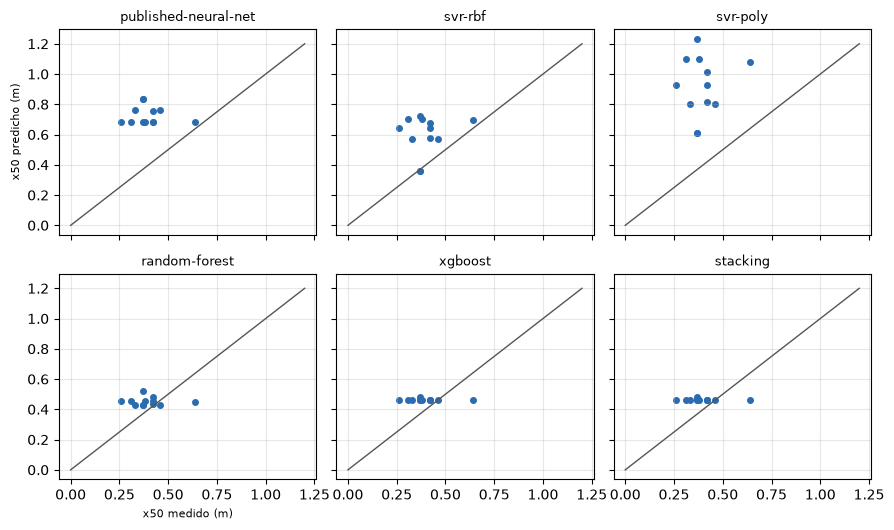

In [5]:
# Tamaño predicho contra medido en Enusa, un panel por brazo aprendido
measured = np.array([b.x50_m for b in test_rows])
fig, axes = plt.subplots(2, 3, figsize=(9, 5.4), sharex=True, sharey=True)
for ax, name in zip(axes.flat, learned):
    predicted = np.array([p.x50_m for p in results[name]])
    ax.scatter(measured, predicted, s=16, color="#2b6cb0")
    ax.plot([0, 1.2], [0, 1.2], color="#555", lw=1)
    ax.set_title(name, fontsize=9)
    ax.grid(alpha=0.3)
axes[1, 0].set_xlabel("x50 medido (m)", fontsize=8)
axes[0, 0].set_ylabel("x50 predicho (m)", fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

**El ajuste y la predicción son toda la historia.** Cada brazo aprendido reproduce la predicción versionada de Enusa hasta los seis decimales que guarda el archivo. El artefacto versionado es un registro fiel de lo que da un ajuste con el sitio fuera, no un cálculo aparte.

**En una campaña que no ha visto, ningún brazo aprendido es exacto.** Los puntajes en Enusa van de malos a extremadamente malos: la red neuronal, el regresor de vectores de soporte radial y el polinómico caen muy por debajo de cero, lo que significa que sus predicciones son peores que la media de las mediciones por un amplio margen, y los brazos basados en árboles quedan cerca de -0,5, mejor que el nulo (cerca de -1,4 en esta campaña) pero aún bajo cero. Una varianza explicada negativa no es un error; dice que la predicción está más lejos de los datos que una constante.

**Por qué los números son tan extremos.** Los tamaños medidos de Enusa varían poco (la misma razón por la que el brazo clásico puntuó mal dentro de una campaña), así que un error absoluto pequeño dividido por una dispersión pequeña da un puntaje muy negativo. Las columnas de RMSE y sesgo son la lectura más justa para una campaña: muestran errores del orden de un decímetro, y el signo del sesgo dice si el brazo sobre o subpredice.

**Qué no muestra esto.** Una campaña excluida es una prueba de un brazo. El cuaderno siguiente repite el ejercicio para cada campaña y cada brazo de la escalera y agrupa el resultado, que es el único puntaje con el que el producto encabeza.

## Resumen

- Los brazos aprendidos se ajustan con las filas de nueve campañas y predicen la décima; el artefacto versionado registra exactamente eso.
- En Enusa la red y los regresores de vectores de soporte puntúan muy por debajo de cero y los brazos basados en árboles cerca de -0,5; una campaña es una prueba pequeña.
- Siguiente: el cuaderno 02 corre los catorce brazos por los diez pliegues y explica cada negativa.

## Referencias

- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (la red de retropropagación)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (regresión de vectores de soporte, rbf)
- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (vectores de soporte polinómico, bosque, boosting, apilamiento)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/